# Multi-regions synthesis — overshoot by region (CBA vs PBA)

"Overshoot / Safe Operating Space" figure for the 2019 geographies
(France / EU27 / World / regions, `2019_*` folders). For each scenario, 2
bubbles per LP:
- solid bubble: **consumption-based** accounting (CBA, `d_cba.pkl`)
- hatched bubble: **production-based** accounting (PBA, `F_x_dom.pkl`, domestic part only)

Generates `figures/overshoot_safe_operating_space_by_region.png`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

notebooks_dir = Path.cwd()
while not (notebooks_dir / "planefr_lib").exists() and notebooks_dir != notebooks_dir.parent:
    notebooks_dir = notebooks_dir.parent
if str(notebooks_dir) not in sys.path:
    sys.path.insert(0, str(notebooks_dir))

import matplotlib.pyplot as plt

from planefr_lib import config, io, processing
from planefr_lib.plot_overshoot import create_overshoot_safe_space_figure_by_region

Failed to read module file 'c:\Users\Arnaud\AppData\Local\Programs\Python\Python314\Lib\_strptime.py' for module '_strptime': UnicodeDecodeError
Traceback (most recent call last):
  File "C:\Users\Arnaud\AppData\Roaming\Python\Python314\site-packages\IPython\core\extensions.py", line 62, in load_extension
    return self._load_extension(module_str)
           ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^
  File "C:\Users\Arnaud\AppData\Roaming\Python\Python314\site-packages\IPython\core\extensions.py", line 77, in _load_extension
    mod = import_module(module_str)
  File "c:\Users\Arnaud\AppData\Local\Programs\Python\Python314\Lib\importlib\__init__.py", line 88, in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 1398, in _gcd_import
  File "<frozen importlib._bootstrap>", line 1371, in _find_and_load
  File "<frozen importlib._bootstrap>", line 1335, in _find_

## 1. Loading the data and per-capita computation

In [2]:
cf_df = io.load_characterization_factors()
thresholds_df = io.load_thresholds()
pop_df = io.load_population_df()

# Unlike the other notebooks: only the 2019_* folders (2019_FR / 2019_W /
# 2019_EU27...), to compare geographies rather than scenarios.
scenario_folders = config.get_scenario_folders(exclude_2019=False, exclude_others=True)
scenario_names = [f.name for f in scenario_folders]
print(f"Scenarios found ({len(scenario_folders)}): {scenario_names}")

Scenarios found (4): ['2019_EU27', '2019_FR', '2019_W', '2019_WF']


c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\config.py:140: UserWarning: Group 'no_SSP' does not contain Base_year_2015: the reference scenario (REFERENCE_SCENARIO_IDX) will be the first one in alphabetical order.
  warnings.warn(


In [3]:
all_scenarios_data = []
for scenario_folder in scenario_folders:
    print(f"Processing: {scenario_folder.name}")
    data = processing.process_scenario_per_capita(scenario_folder, cf_df, thresholds_df, pop_df)
    print(f"  Indicators computed: {list(data.keys())}")
    all_scenarios_data.append(data)

print(f"\n{len(all_scenarios_data)} scenarios processed.")

Processing: 2019_EU27
  Indicators computed: ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']
Processing: 2019_FR
  Indicators computed: ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']
Processing: 2019_W
  Indicators computed: ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']
Processing: 2019_WF
  Indicators computed: ['N surplus', 'P surplus', 'Blue water consumption', 'Cropland use', 'Agricultural land', 'GHG emissions', 'Biodiversity loss - PDF', 'Biodiversity loss - HANPP', 'Raw material consumption']

4 scenarios processed.


## 2. Overshoot figure in absolute values, by country/region (EPC budget)

Variant in absolute values (nothing is divided by the population): the budget
of each scenario is the world budget multiplied by its share in
`budget_shares.xlsx` (UN EPC column, row of the EXIOBASE code deduced from the
folder name). See `create_overshoot_safe_space_figure_by_region`.

c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\plot_overshoot.py:832: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[left_rect, 0.06, 0.98, top_rect])


Figure saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\overshoot_safe_operating_space_by_region.png


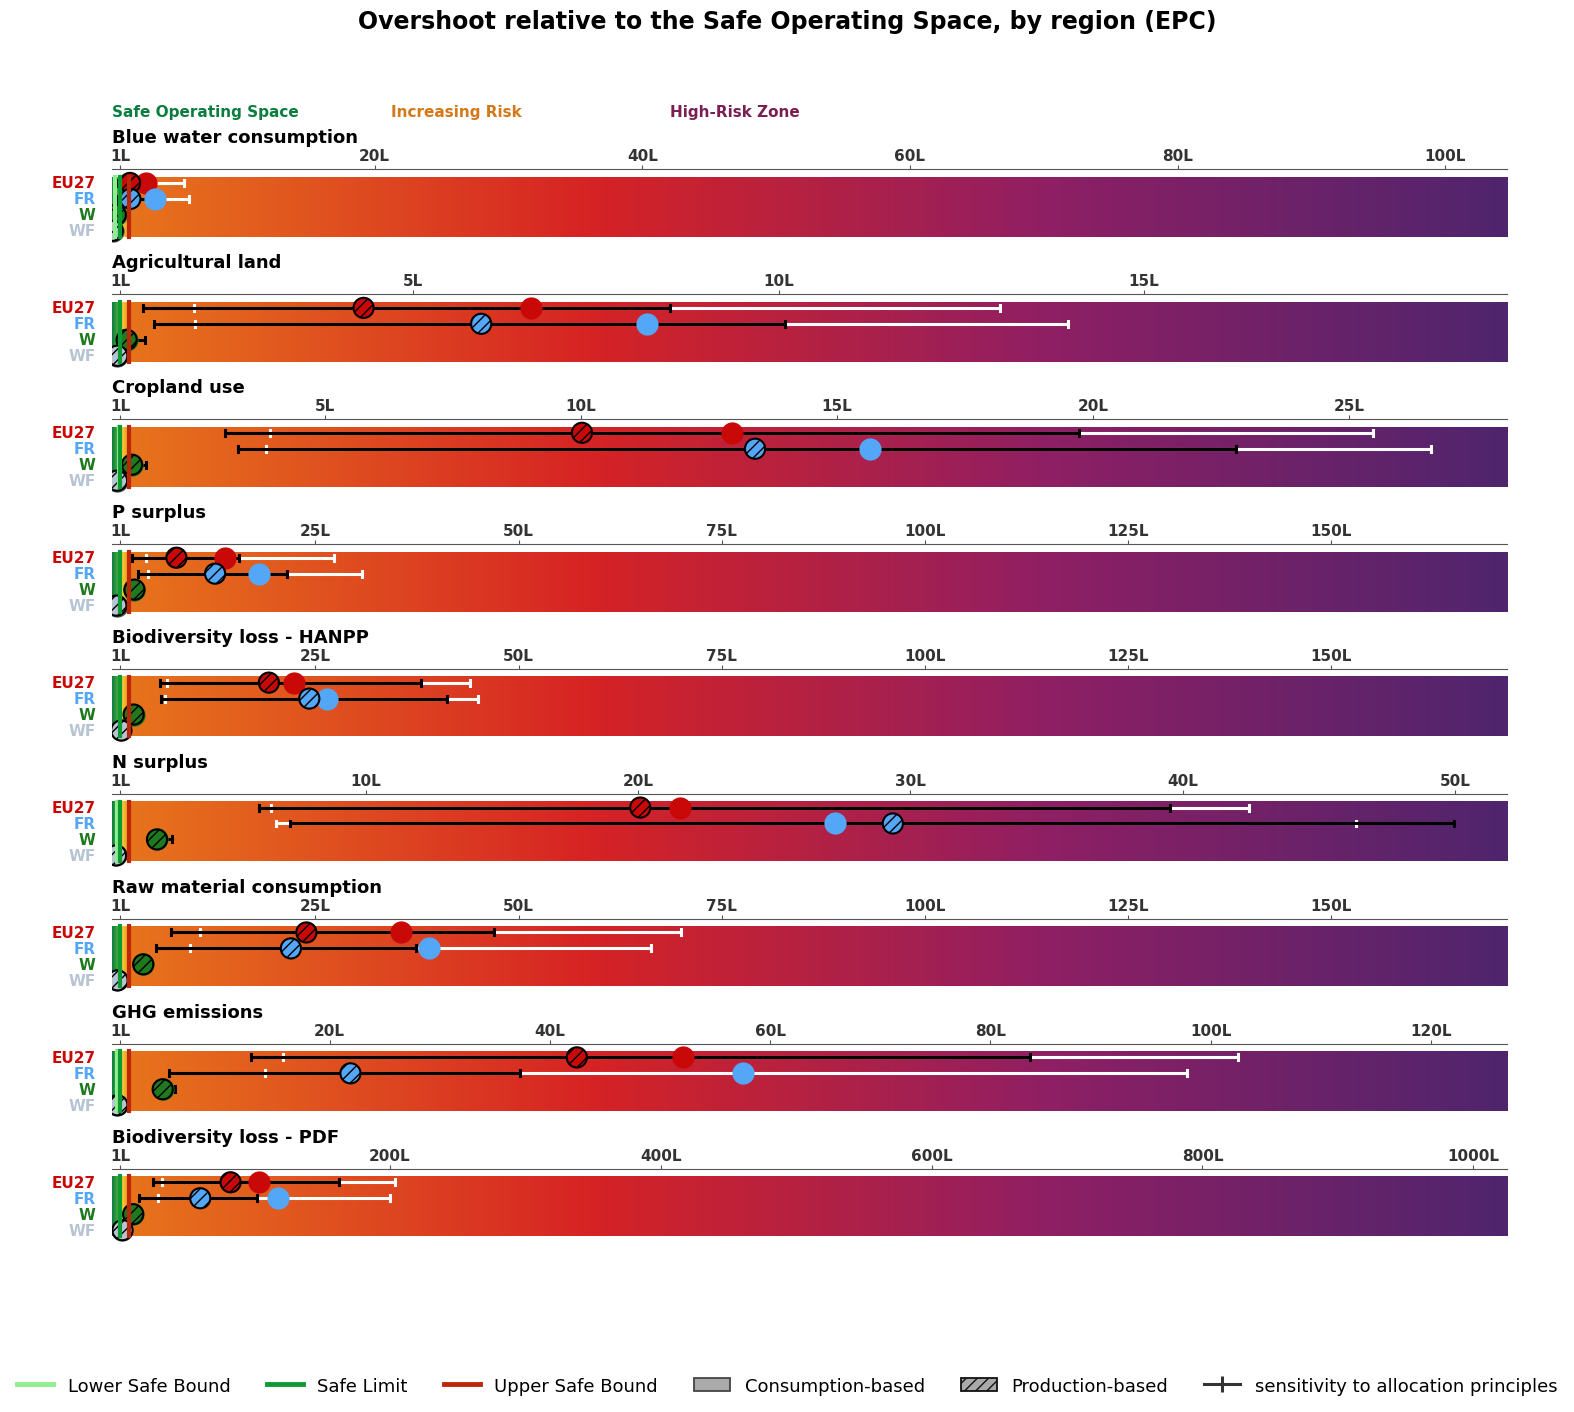

In [5]:
shares_df = io.load_budget_shares_df()
data_absolute = [processing.process_scenario_absolute(f, cf_df, thresholds_df) for f in scenario_folders]

fig = create_overshoot_safe_space_figure_by_region(
    all_scenarios_data=data_absolute, thresholds_df=thresholds_df, shares_df=shares_df,
    scenario_names=scenario_names,
    x_main_max=6, show_value_bounds=False, show_pba=True,
    show_value_overshoot=True, title_above_bar=True,
    title="Overshoot relative to the Safe Operating Space, by region (EPC)",
    sharing_principle="CTR", sensitivity=True, scale_UB=True,
    pop_df=pop_df,  # sensitivity of W: per-capita limit depending on the population period
)

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
output_path = config.FIGURES_DIR / "overshoot_safe_operating_space_by_region.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Figure saved: {output_path}")
plt.show()